In [154]:
import numpy as np
import matplotlib.pyplot as plt

In [218]:
def read_frame_with_stride(raw_file, frame_idx=0, width=4056, height=3040, stride=8128, dtype=np.uint16):
    """
    Reads a single frame from a multi-frame raw file with stride-aware unpacking.
    Assumes 16-bit unpacked SBGGR16 format.
    
    Parameters:
        raw_file (str): Path to the .raw file.
        frame_idx (int): Index of the frame to read (0-based).
        width (int): Width of the image in pixels.
        height (int): Height of the image in pixels.
        stride (int): Bytes per row (may be more than width * 2).
        dtype: Data type of the pixel values (np.uint16 for SBGGR16).
    Returns:
        np.ndarray: Image array of shape (height, width).
    """
    row_bytes = stride
    frame_bytes = row_bytes * height

    with open(raw_file, 'rb') as f:
        f.seek(frame_idx * frame_bytes)
        raw_frame = f.read(frame_bytes)

    # Convert to 1D array of 16-bit unsigned ints
    raw_data = np.frombuffer(raw_frame, dtype=dtype)

    # Reshape to (height, stride//2) and crop to (height, width)
    full_width = stride // 2  # since each pixel is 2 bytes
    raw_2d = raw_data.reshape((height, full_width))
    image = raw_2d[:, :width]  # Crop to actual width

    return image

def visualize_bayer_pattern(image, x_start=0, y_start=0, size=40):
    """
    Visualize a cropped region of the Bayer raw image.
    """
    region = image[y_start:y_start+size, x_start:x_start+size]
    plt.figure(figsize=(6, 6))
    plt.imshow(region, cmap='gray', interpolation='nearest')
    plt.title(f"Cropped Bayer Pattern Region ({x_start},{y_start})")
    plt.colorbar()
    plt.show()

In [217]:
raw_path = "./g_10ms.raw"
frame = read_frame_with_stride(raw_path, frame_idx=0)
np.min(frame-np.min(frame)),np.max(frame-np.min(frame))

(0, 5392)

In [216]:
raw_path = "./diffusor1ms.raw"
frame = read_frame_with_stride(raw_path, frame_idx=0)
np.min(frame-np.min(frame)),np.max(frame-np.min(frame))

(0, 1120)

In [240]:
clean_shutter_toPlot =[]
for ms in [1,10,20,30,50,100]:
    raw_path = f"g_{str(ms)}ms.raw"
    frame = read_frame_with_stride(raw_path, frame_idx=0)
    #im = plt.imshow(frame,cmap='gray')
    #plt.colorbar(im)
    #plt.title('raw',fontsize=16)
    #figname = raw_path.replace('.raw','.png')
    #plt.savefig(figname)
    print(f'min: {np.min(frame)}, max: {np.max(frame)}, max_wo_darkNoise: {np.max(frame)-np.min(frame)}, shutter: {ms}ms')
    
    clean_shutter_toPlot.append(np.max(frame)-np.min(frame))
    del frame
    #plt.close()

min: 3904, max: 4880, max_wo_darkNoise: 976, shutter: 1ms
min: 3888, max: 9456, max_wo_darkNoise: 5568, shutter: 10ms
min: 4048, max: 14224, max_wo_darkNoise: 10176, shutter: 20ms
min: 4240, max: 19104, max_wo_darkNoise: 14864, shutter: 30ms
min: 4640, max: 28640, max_wo_darkNoise: 24000, shutter: 50ms
min: 5408, max: 52096, max_wo_darkNoise: 46688, shutter: 100ms


Text(0, 0.5, '16bit raw readout')

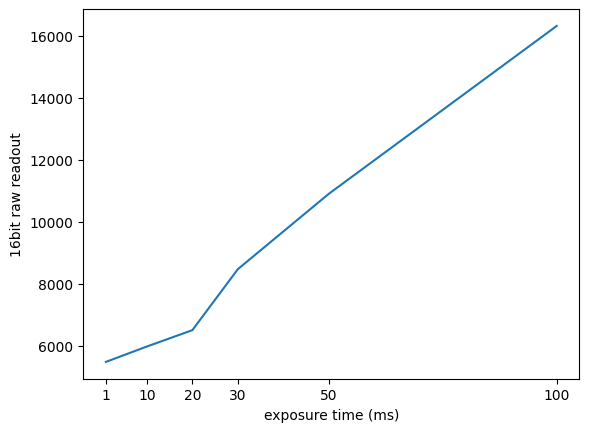

In [241]:
shutters= [1,10,20,30,50,100]
plt.plot(shutters,clean_gain_toPlot)
plt.xticks(shutters,shutters)
plt.xlabel('exposure time (ms)')
plt.ylabel('16bit raw readout')

In [237]:
ags=[1,1.1,1.2,1.5,2,3]

In [233]:
clean_gain_toPlot = []
for ms in [10]:
    for ag in [1,1.1,1.2,1.5,2,3]:
        raw_path = f"g_{str(ms)}ms_gain{str(ag)}.raw"
        frame = read_frame_with_stride(raw_path, frame_idx=0)
        #im = plt.imshow(frame,cmap='gray')
        #plt.colorbar(im)
        #plt.title('raw',fontsize=16)
        #figname = raw_path.replace('.raw','.png')
        #plt.savefig(figname)
        print(f'min: {np.min(frame)}, max: {np.max(frame)}, max_wo_darkNoise: {np.max(frame)-np.min(frame)}, gain: {ag}, shutter: {ms}ms')
        #del frame
        clean_gain_toPlot.append(np.max(frame)-np.min(frame))
        
        #plt.close()

min: 3920, max: 9408, max_wo_darkNoise: 5488, gain: 1, shutter: 10ms
min: 3984, max: 9968, max_wo_darkNoise: 5984, gain: 1.1, shutter: 10ms
min: 3920, max: 10432, max_wo_darkNoise: 6512, gain: 1.2, shutter: 10ms
min: 3616, max: 12096, max_wo_darkNoise: 8480, gain: 1.5, shutter: 10ms
min: 3760, max: 14672, max_wo_darkNoise: 10912, gain: 2, shutter: 10ms
min: 3488, max: 19808, max_wo_darkNoise: 16320, gain: 3, shutter: 10ms


Text(0.5, 0, 'analoggain')

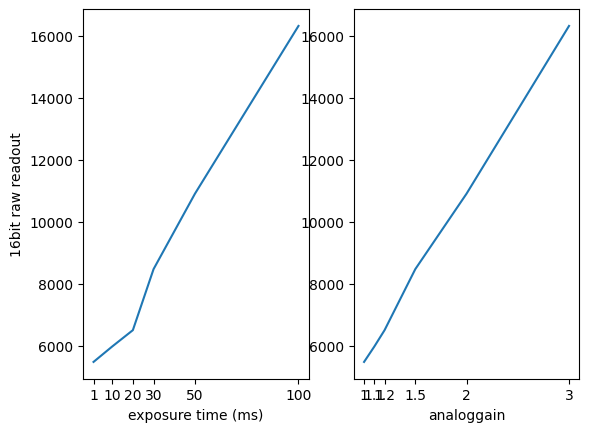

In [243]:
plt.subplot(121)
shutters= [1,10,20,30,50,100]
plt.plot(shutters,clean_gain_toPlot)
plt.xticks(shutters,shutters)
plt.xlabel('exposure time (ms)')
plt.ylabel('16bit raw readout')
plt.subplot(122)
plt.plot(ags,clean_gain_toPlot)
plt.xticks(ags,ags)
plt.xlabel('analoggain')
#plt.ylabel('16bit raw readout')

In [215]:
np.min(frame-np.min(frame)),np.max(frame-np.min(frame))

(0, 5392)

Text(0.5, 1.0, 'raw')

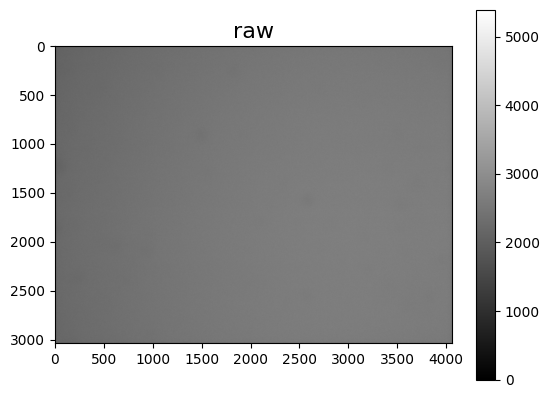

In [214]:
im = plt.imshow(frame-np.min(frame),cmap='gray')
plt.colorbar(im)
plt.title('raw',fontsize=16)

Text(0.5, 1.0, 'raw')

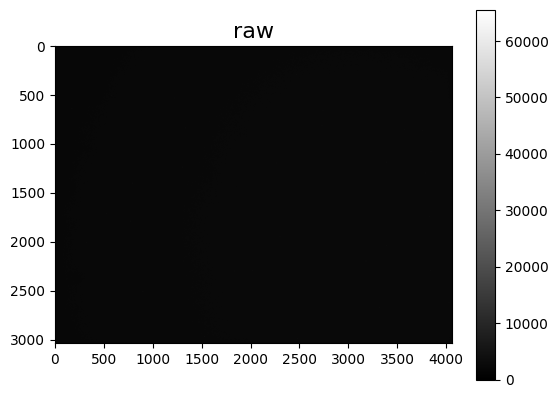

In [187]:
im = plt.imshow(frame-4096,cmap='gray')
plt.colorbar(im)
plt.title('raw',fontsize=16)

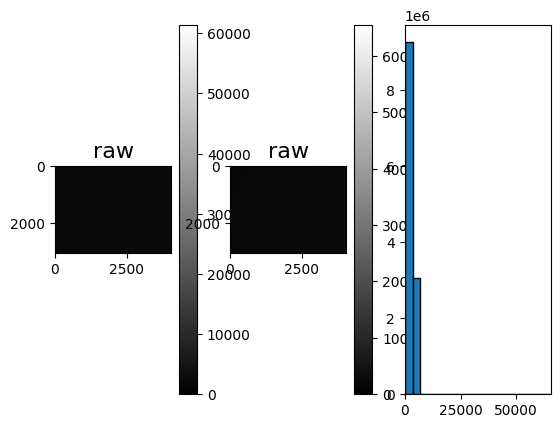

In [198]:
plt.subplot(131)
im = plt.imshow(frame,cmap='gray',vmin=0, vmax=65520-4096)
plt.colorbar(im)
plt.title('raw',fontsize=16)
plt.subplot(132)
im = plt.imshow(frame,cmap='gray')
plt.colorbar(im)
plt.title('raw',fontsize=16)
plt.subplot(133)
data = frame.flatten()

# Define bin edges
#bin_edges = np.linspace(data.min(), data.max(), 20)
bin_edges = np.linspace(0, 65520, 20)

# Get counts per bin
counts, edges = np.histogram(data, bins=bin_edges)

# Plot
plt.hist(data, bins=edges, edgecolor='black')
plt.xlim([0,65520])
plt.show()

In [190]:
np.max(frame.flatten())

9392

In [191]:
np.log2(np.max(frame.flatten()))

13.197217

In [192]:
np.power(2,16)

65536

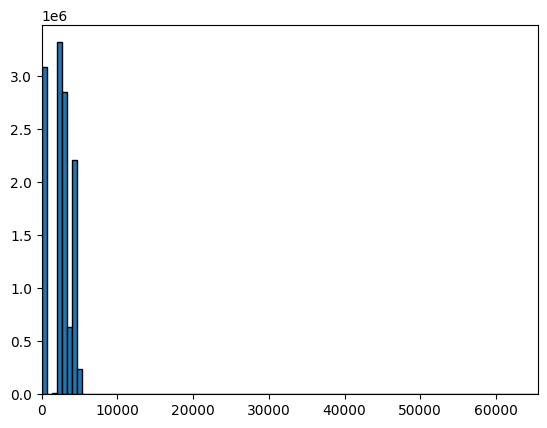

[0.000, 661.818): 3082521
[661.818, 1323.636): 0
[1323.636, 1985.455): 7435
[1985.455, 2647.273): 3313707
[2647.273, 3309.091): 2847370
[3309.091, 3970.909): 634794
[3970.909, 4632.727): 2206533
[4632.727, 5294.545): 237839
[5294.545, 5956.364): 2
[5956.364, 6618.182): 0
[6618.182, 7280.000): 0
[7280.000, 7941.818): 0
[7941.818, 8603.636): 0
[8603.636, 9265.455): 0
[9265.455, 9927.273): 0
[9927.273, 10589.091): 0
[10589.091, 11250.909): 0
[11250.909, 11912.727): 0
[11912.727, 12574.545): 0
[12574.545, 13236.364): 0
[13236.364, 13898.182): 0
[13898.182, 14560.000): 0
[14560.000, 15221.818): 0
[15221.818, 15883.636): 0
[15883.636, 16545.455): 0
[16545.455, 17207.273): 0
[17207.273, 17869.091): 0
[17869.091, 18530.909): 0
[18530.909, 19192.727): 0
[19192.727, 19854.545): 0
[19854.545, 20516.364): 0
[20516.364, 21178.182): 0
[21178.182, 21840.000): 0
[21840.000, 22501.818): 0
[22501.818, 23163.636): 0
[23163.636, 23825.455): 0
[23825.455, 24487.273): 0
[24487.273, 25149.091): 0
[25149.091,

In [199]:
import numpy as np
import matplotlib.pyplot as plt

data = frame.flatten()

# Define bin edges
#bin_edges = np.linspace(data.min(), data.max(), 20)
bin_edges = np.linspace(0, 65520, 100)

# Get counts per bin
counts, edges = np.histogram(data, bins=bin_edges)

# Plot
plt.hist(data, bins=edges, edgecolor='black')
plt.xlim([0,65520])
plt.show()

# Inspect counts per range
for i in range(len(counts)):
    print(f"[{edges[i]:.3f}, {edges[i+1]:.3f}): {counts[i]}")


In [93]:
top49 = np.sort(data)[-37:]

In [49]:
top49

array([65520, 65520, 65520, 65520, 65520, 65520, 65520, 65520, 65520,
       65520, 65520, 65520, 65520, 65520, 65520, 65520, 65520, 65520,
       65520, 65520, 65520, 65520, 65520, 65520, 65520, 65520, 65520,
       65520, 65520, 65520, 65520, 65520, 65520, 65520, 65520, 65520,
       65520], dtype=uint16)

In [15]:
# Example usage:
raw_path = "./cam0_raw_zz.raw"
frame = read_frame_with_stride(raw_path, frame_idx=0)
#visualize_bayer_pattern(frame)# x_start=100, y_start=100, size=40)

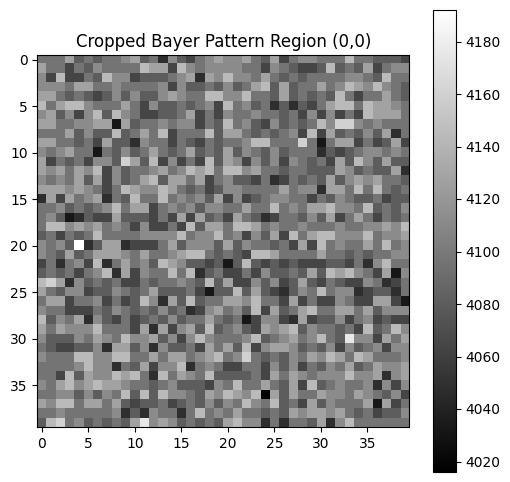

In [10]:
visualize_bayer_pattern(frame)# x_start=100, y_start=100, size=40)